In [1]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.vectorstores import Chroma
from langchain_ollama import OllamaEmbeddings, ChatOllama
from IPython.display import Markdown
import os
from pathlib import Path
from langchain.tools import tool
from typing import List,TypedDict

C:\Users\Ousmane\AppData\Local\Temp\ipykernel_23160\3674789300.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFDirectoryLoader


from langchain_community.document_loaders import PyPDFDirectoryLoader
# Path of all Documents : Abount AI Initiative
ai_initiative_pdf_paths = [ f"./resources/{file}" for file in os.listdir("./resources")]

In [2]:
# Creating PDF loader object

pdf_dir = Path.cwd() / "ressources"

print("Répertoire :", pdf_dir)
print("Existe :", pdf_dir.exists())
print("PDF trouvés :", list(pdf_dir.glob("*.pdf")))

loader = PyPDFDirectoryLoader(path=str(pdf_dir))
documents = loader.load()

print("Nombre de documents/pages :", len(documents))
print("Texte extrait :", sum(len(doc.page_content.strip()) for doc in documents))

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)

ai_initiative_chunks = text_splitter.split_documents(documents)

print("Number of chunks created:", len(ai_initiative_chunks))

Répertoire : c:\Users\babacar\agentic_rag\ressources
Existe : True
PDF trouvés : [WindowsPath('c:/Users/babacar/agentic_rag/ressources/Synthèse de la stratégie IA du Sénégal.pdf')]
Nombre de documents/pages : 20
Texte extrait : 103444
Number of chunks created: 134


In [3]:
### Step 4: Create Vector Store with Embeddings
# Initialize Ollama embedding model
embedding_model = OllamaEmbeddings(
model="embeddinggemma:latest"
)
# Create vector store from documents
vectorstore = Chroma.from_documents(
documents=ai_initiative_chunks,
embedding=embedding_model,
collection_name="AI_Initiatives"
)
# Create retriever for similarity search
# which fetches 10 relevant chunks
retriever = vectorstore.as_retriever(
search_type="similarity",
search_kwargs={"k": 10}
)

In [4]:
### Step 5: Test RAG Retrieval (Manual)
# Test query
test_query = "What AI projects is Senegal working on?"
print(f"🔍 Test Query: {test_query}")
print("="*80)
# Retrieve relevant documents
relevant_docs = retriever.invoke(test_query)
print(f"\n Retrieved {len(relevant_docs)} relevant chunks:\n")
# Display top 3 results
for i, doc in enumerate(relevant_docs[:3], 1):
    print(f"📄 Result {i}:")
    print(f" Source: {doc.metadata.get('source', 'Unknown')}")
    print(f" Page: {doc.metadata.get('page', 'Unknown')}")
    print(f" Content: {doc.page_content[:100]}...")
    print("-"*80 + "\n")

🔍 Test Query: What AI projects is Senegal working on?

 Retrieved 10 relevant chunks:

📄 Result 1:
 Source: c:\Users\babacar\agentic_rag\ressources\Synthèse de la stratégie IA du Sénégal.pdf
 Page: 3
 Content: STRATÉGIE NATIONALE ET FEUILLE DE ROUTE DU SÉNÉGAL  
SUR L’INTELLIGENCE ARTIFICIELLE À L’HORIZON 202...
--------------------------------------------------------------------------------

📄 Result 2:
 Source: c:\Users\babacar\agentic_rag\ressources\Synthèse de la stratégie IA du Sénégal.pdf
 Page: 4
 Content: STRATÉGIE NATIONALE ET FEUILLE DE ROUTE DU SÉNÉGAL  
SUR L’INTELLIGENCE ARTIFICIELLE À L’HORIZON 202...
--------------------------------------------------------------------------------

📄 Result 3:
 Source: c:\Users\babacar\agentic_rag\ressources\Synthèse de la stratégie IA du Sénégal.pdf
 Page: 15
 Content: STRATÉGIE NATIONALE ET FEUILLE DE ROUTE DU SÉNÉGAL  
SUR L’INTELLIGENCE ARTIFICIELLE À L’HORIZON 202...
-------------------------------------------------------------------

In [5]:
@tool
def retriever_tool(query: str) -> str:
    """ Interrogez la base de données privée des rapports d’analystes et des documents sur les initiatives en IA.
    Cet outil alimenté par RAG effectue des recherches dans des documents internes de l'etat concernant les initiatives en IA,
    les projets de recherche, les domaines d’innovation et les investissements technologiques stratégiques.
    Utilisez cet outil lorsque vous avez besoin d’informations sur :
    - Les projets de recherche et les initiatives en IA de l’entreprise
    - Les domaines d’innovation en IA et les axes prioritaires
    - Les feuilles de route technologiques et les plans futurs
    - Les calendriers et les détails de projets d’IA spécifiques
    Args:
    query: Requête en langage naturel sur les initiatives en IA de l’entreprise
    (p. ex., « Sur quels projets d’IA Microsoft travaille-t-elle ? »,
    « Les domaines de recherche en IA de NVIDIA »,
    « La chronologie de l’IA chez Amazon »)
    Returns:
    str: Réponse détaillée fondée sur des rapports privés d’analystes avec citations des sources
    """
    try:
        # Retrieve relevant document chunks
        relevant_document_chunks = retriever.invoke(query)
        context_list = [d.page_content for d in relevant_document_chunks]
        context_for_query = ". ".join(context_list)
        return context_for_query
    except Exception as e:
        return f"Error querying private database: {str(e)}"

In [6]:
model = ChatOllama(model="llama3.2", temperature=0)
tools = [retriever_tool]
llm_with_tools = model.bind_tools(tools)

State and System message

In [7]:
import logging
from typing import Annotated, Sequence, Literal
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain.messages import SystemMessage, HumanMessage, AIMessage

In [8]:
# Configure logging to see agent's decision-making process
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    datefmt='%H:%M:%S'
)

logger = logging.getLogger(__name__)

In [9]:
class SimpleAgentState(TypedDict):
    """
    State for the financial research agent.
    Tracks the conversation history with message accumulation.
    """
    messages: Annotated[Sequence, add_messages]

In [10]:
agentic_rag_system_message ="""
Vous êtes un assistant spécialisé dans l’examen des
initiatives en IA des entreprises et dans la fourniture
de réponses exactes fondées sur le contexte fourni.
Les données fornies par l’utilisateur incluront tout le
contexte nécessaire pour répondre à sa question.
Le contexte contient des références à des initiatives,
projets ou programmes d’IA spécifiques d’entreprises,
pertinents pour la requête de l’utilisateur.
Répondez uniquement en utilisant le contexte fourni.
N’ajoutez pas d’informations externes et ne mentionnez
pas le contexte dans votre réponse.
Citez toujours de quelle entreprise provient
l’information.
Si la réponse ne peut pas être trouvée dans le contexte,
répondez par : "Je ne sais pas - cette information n’est
pas disponible dans nos rapports d’analystes."
"""

Agent Node

In [11]:
def agent_node(state: SimpleAgentState) -> dict:
    """Agent node that calls the LLM with system prompt and current state."""
    logger.info("AGENT NODE: Processing request...")
    # Prepare messages with system prompt
    system_msg = SystemMessage(content=agentic_rag_system_message)
    messages = [system_msg] + list(state["messages"])
    # Invoke model
    logger.info("Calling LLM with tools...")
    response = llm_with_tools.invoke(messages)
    # Log if agent wants to use tools
    if hasattr(response, 'tool_calls') and response.tool_calls:
        logger.info(f"✓ Agent decided to use {len(response.tool_calls)} tool(s)")
        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info(f" {i}. {tool_call['name']}")
    else:
        logger.info(" ✓ Agent generated final response (no tools needed)")
    return {"messages": [response]}

Condition de routage

In [12]:
def should_continue(state: SimpleAgentState) -> Literal["tools", "end"]:
    """Determines whether to continue to tools or end."""
    last_message = state["messages"][-1]
    if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
        logger.info("🔀 ROUTING: Continuing to TOOLS node")
        return "tools"
    logger.info("ROUTING: Ending workflow (final response ready)")
    return "end"

creat, compile and display the Graph

In [13]:
# Create workflow
from langgraph.graph import StateGraph
workflow = StateGraph(SimpleAgentState)
# Create tool node with logging
original_tool_node = ToolNode(tools)
def tool_node_with_logging(state):
    logger.info("TOOL NODE: Executing tools...")
    result = original_tool_node.invoke(state)
    logger.info(f"Tools executed successfully")
    return result
# Add nodes to graph
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)
# Set entry point
workflow.set_entry_point("agent")

22:15:39 [INFO] ✅ Enhanced agent created successfully



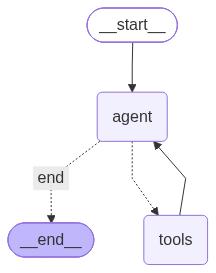

In [14]:
# Add conditional edge from agent
from langgraph.graph import END
from IPython.display import Image, display

# Route from agent either to tools or to END
workflow.add_conditional_edges(
    "agent",
    should_continue,
    {"tools": "tools", "end": END},
)
# Add edge from tools back to agent
workflow.add_edge("tools", "agent")
graph = workflow.compile()
logger.info("✅ Enhanced agent created successfully\n")
display(Image(graph.get_graph().draw_mermaid_png()))

Tester l'application Agentic RAG

In [15]:
print("="*80)
print("TEST 5: Enhanced Agent with RAG - AI Research Activity Check")
print("="*80 + "\n")
# Test query that requires AI research information
query = "Provide a comprehensive investment analysis for Senegal their AI research initiatives"
print(f"Query: {query}\n")
print("-"*80 + "\n")
result = graph.invoke(
{"messages": [HumanMessage(content=query)]}
)
print("\n🤖 ENHANCED AGENT RESPONSE (with RAG):")
print("="*80)
print(display(Markdown(result["messages"][-1].content)))
print("\n" + "="*80)
print("\n✅ Notice: The agent now includes:")
print(" • AI research projects from private analyst reports")
print(" • Specific AI initiative details")
print(" • Integration of financial + AI research data")
print(" • Comprehensive investment recommendation")

22:15:41 [INFO] AGENT NODE: Processing request...
22:15:41 [INFO] Calling LLM with tools...


TEST 5: Enhanced Agent with RAG - AI Research Activity Check

Query: Provide a comprehensive investment analysis for Senegal their AI research initiatives

--------------------------------------------------------------------------------



22:16:03 [INFO] HTTP Request: POST http://127.0.0.1:11434/api/chat "HTTP/1.1 200 OK"
22:16:03 [INFO] ✓ Agent decided to use 1 tool(s)
22:16:03 [INFO]  1. retriever_tool
22:16:03 [INFO] 🔀 ROUTING: Continuing to TOOLS node
22:16:03 [INFO] TOOL NODE: Executing tools...
22:16:10 [INFO] HTTP Request: POST http://127.0.0.1:11434/api/embed "HTTP/1.1 200 OK"
22:16:10 [INFO] Tools executed successfully
22:16:10 [INFO] AGENT NODE: Processing request...
22:16:10 [INFO] Calling LLM with tools...
22:16:28 [INFO] HTTP Request: POST http://127.0.0.1:11434/api/chat "HTTP/1.1 200 OK"
22:16:29 [INFO]  ✓ Agent generated final response (no tools needed)
22:16:29 [INFO] ROUTING: Ending workflow (final response ready)



🤖 ENHANCED AGENT RESPONSE (with RAG):


Je ne sais pas - cette information n’est pas disponible dans nos rapports d’analystes.

None


✅ Notice: The agent now includes:
 • AI research projects from private analyst reports
 • Specific AI initiative details
 • Integration of financial + AI research data
 • Comprehensive investment recommendation
